# Neural Machine Translation with Attention — Demo
English → French, Bi-LSTM encoder + Bahdanau attention, trained on Multi30k.

Run `python train.py` first to create `checkpoints/attention.pt`.

In [1]:
import torch, matplotlib.pyplot as plt
from evaluate import load_checkpoint, translate

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model, src_vocab, tgt_vocab = load_checkpoint('checkpoints/attention.pt', device)

def show(sentence, beam=5):
    out, src, attn = translate(model, sentence, src_vocab, tgt_vocab, device, beam)
    cols, rows = ['<sos>'] + src + ['<eos>'], out + ['<eos>']
    fig, ax = plt.subplots(figsize=(max(5, .6*len(cols)), max(4, .5*len(rows))))
    ax.imshow(attn.numpy(), cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right'); ax.set_yticks(range(len(rows)), rows)
    ax.set_xlabel('source (EN)'); ax.set_ylabel('generated (FR)')
    ax.set_title(' '.join(out)); plt.tight_layout(); plt.show()

## Adjective–noun reordering
French usually puts colour adjectives *after* the noun — the attention should cross over.

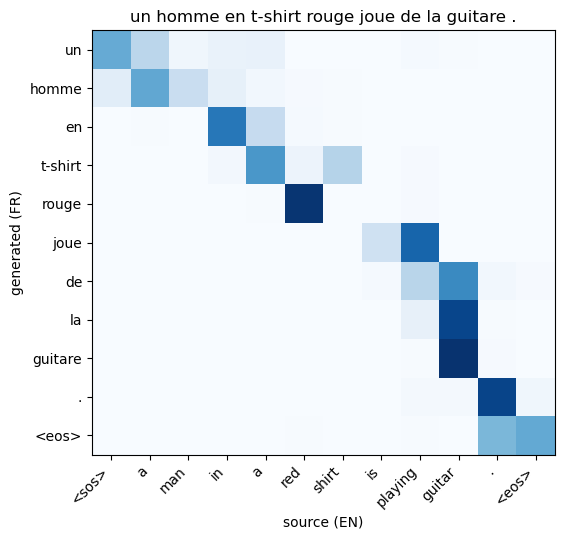

In [2]:
show('A man in a red shirt is playing guitar.')

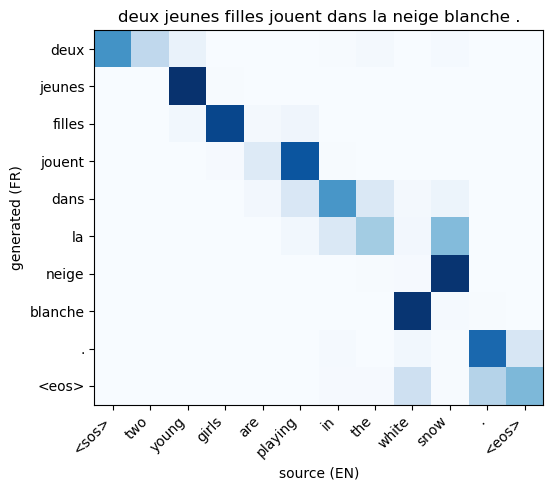

In [3]:
show('Two young girls are playing in the white snow.')

## Try your own (Multi30k is image captions, so describe a scene)

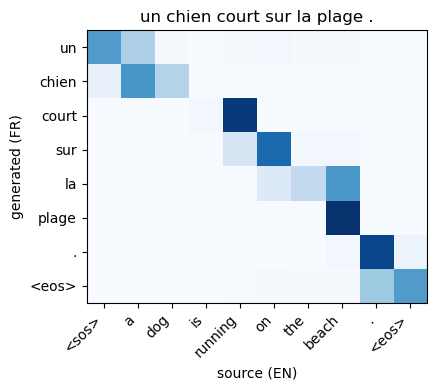

In [4]:
show('A dog is running on the beach.')

## Test-set samples

In [5]:
from data import read_split
en, fr = read_split('test')
for e, f in list(zip(en, fr))[:5]:
    out, _, _ = translate(model, e, src_vocab, tgt_vocab, device)
    print('EN  :', e)
    print('REF :', f)
    print('PRED:', ' '.join(out))
    print()

EN  : A man in an orange hat starring at something.
REF : Un homme avec un chapeau orange regardant quelque chose.
PRED: un homme avec une casquette orange regardant quelque chose .

EN  : A Boston Terrier is running on lush green grass in front of a white fence.
REF : Un terrier de Boston court sur l'herbe verdoyante devant une clôture blanche.
PRED: un terrier de court court sur l' herbe verte devant une clôture blanche .

EN  : A girl in karate uniform breaking a stick with a front kick.
REF : Une fille en tenue de karaté brisant un bâton avec un coup de pied.
PRED: une fille en tenue de karaté donnant un bâton avec un ballon de avant .



EN  : Five people wearing winter jackets and helmets stand in the snow, with snowmobiles in the background.
REF : Cinq personnes avec des vestes d'hiver et des casques sont debout dans la neige, avec des motoneiges en arrière-plan.
PRED: cinq personnes portant des vestes d' hiver et des casques sont debout dans la neige , avec des <unk> en arrière-plan .

EN  : People are fixing the roof of a house.
REF : Des gens réparent le toit d'une maison.
PRED: des gens répare le toit d' une maison .

